In [146]:
import pandas as pd
import matplotlib.pyplot as plt

In [147]:
df_univ_migration = pd.read_csv('../data/processed/university_migration_od.csv')
df_univ_migration.tail()

,year,origin,destination,students
112654,2025,熊本県,沖縄県,28
112655,2025,大分県,沖縄県,35
112656,2025,宮崎県,沖縄県,32
112657,2025,鹿児島県,沖縄県,80
112658,2025,沖縄県,沖縄県,3635


In [148]:
df_ishikawa = df_univ_migration[df_univ_migration['origin'] == '石川県']

In [149]:
# 石川県から関西圏に行くのは何人かを見たらよさそう
# そして、石川県から関東圏も
kanto_region = ['東京都', '神奈川県', '埼玉県', '千葉県', '茨城県', '栃木県', '群馬県']
kansai_region = ['大阪府', '京都府', '滋賀県', '和歌山県', '奈良県', '兵庫県']

In [150]:
# 47都道府県の出身者について、5年おきに関東・関西・中京への進学者数を集計する
# 都道府県ごとの抽出を繰り返さず、後段のgroupbyで一括集計する
# rangeの終端は含まれないため、2025年を含めるには2026を指定する
target_years = range(1975, 2026, 5)
# 単独県のグラフで使う表示対象（集計自体は47都道府県が対象）
origin = '石川県'

# 各都道府県を、集計したい地方名に対応付ける
region_map = {
    destination: '関東地方'
    for destination in kanto_region
}
region_map.update({
    destination: '関西地方'
    for destination in kansai_region
})
chukyo_region = ['愛知県', '三重県', '岐阜県']
region_map.update({
    destination: '中京'
    for destination in chukyo_region
})

# 全出身地・対象年度・関東、関西または中京の進学先だけを一括抽出する
df_region = (
    df_univ_migration[
        df_univ_migration['year'].isin(target_years)
        & df_univ_migration['destination'].isin(region_map)
    ]
    # 進学先の都道府県名を、関東地方・関西地方・中京へ置き換える
    .assign(destination=lambda df: df['destination'].map(region_map))
    # 同じ年度・出身地・地方のstudentsを合計する
    .groupby(['year', 'origin', 'destination'], as_index=False)['students']
    .sum()
    # 年度と地方の順に並べ、連番のインデックスを振り直す
    .sort_values(['year', 'destination'])
    .reset_index(drop=True)
)

# 分母となる、各出身地の全進学先への大学進学者数を年度ごとに集計する
total_students = (
    df_univ_migration[
        df_univ_migration['year'].isin(target_years)
    ]
    .groupby(['year', 'origin'], as_index=False)['students']
    .sum()
    .rename(columns={'students': '全大学進学者数'})
)

# 地域別の人数を横持ちにして、関東・関西・中京の割合を計算する
region_shares = (
    df_region
    .pivot(index=['year', 'origin'], columns='destination', values='students')
    .fillna(0)
    .reset_index()
    .rename(columns={
        '関東地方': '関東進学者数',
        '関西地方': '関西進学者数',
        '中京': '中京進学者数',
    })
    .merge(total_students, on=['year', 'origin'], validate='one_to_one')
)
region_shares['関東進学割合'] = (
    region_shares['関東進学者数'] / region_shares['全大学進学者数']
)
region_shares['関西進学割合'] = (
    region_shares['関西進学者数'] / region_shares['全大学進学者数']
)
region_shares['中京進学割合'] = (
    region_shares['中京進学者数'] / region_shares['全大学進学者数']
)

# 地方別の人数と割合を、元の縦長データに年度・出身地単位で付加する
df_region = df_region.merge(
    region_shares[
        [
            'year', 'origin', '全大学進学者数',
            '関東進学割合', '関西進学割合', '中京進学割合',
        ]
    ],
    on=['year', 'origin'],
    validate='many_to_one',
)

# 各年度の全都道府県を合算し、全国全体の進学率を「全国平均」として追加する
national_region = (
    df_region
    .groupby(['year', 'destination'], as_index=False)['students']
    .sum()
    .assign(origin='全国平均')
)
national_total_students = (
    total_students
    .groupby('year', as_index=False)['全大学進学者数']
    .sum()
)
national_region_shares = (
    national_region
    .pivot(index='year', columns='destination', values='students')
    .fillna(0)
    .reset_index()
    .rename(columns={
        '関東地方': '関東進学者数',
        '関西地方': '関西進学者数',
        '中京': '中京進学者数',
    })
    .merge(national_total_students, on='year', validate='one_to_one')
)
national_region_shares['関東進学割合'] = (
    national_region_shares['関東進学者数']
    / national_region_shares['全大学進学者数']
)
national_region_shares['関西進学割合'] = (
    national_region_shares['関西進学者数']
    / national_region_shares['全大学進学者数']
)
national_region_shares['中京進学割合'] = (
    national_region_shares['中京進学者数']
    / national_region_shares['全大学進学者数']
)
national_region = national_region.merge(
    national_region_shares[
        [
            'year', '全大学進学者数',
            '関東進学割合', '関西進学割合', '中京進学割合',
        ]
    ],
    on='year',
    validate='many_to_one',
)
df_region = pd.concat([df_region, national_region], ignore_index=True)
df_region = df_region.sort_values(
    ['year', 'origin', 'destination']
).reset_index(drop=True)

df_region

,year,origin,destination,students,全大学進学者数,関東進学割合,関西進学割合,中京進学割合
0,1975,三重県,中京,2447,5817,0.248410,0.259928,0.420664
1,1975,三重県,関東地方,1445,5817,0.248410,0.259928,0.420664
2,1975,三重県,関西地方,1512,5817,0.248410,0.259928,0.420664
3,1975,京都府,中京,306,9643,0.085865,0.824847,0.031733
4,1975,京都府,関東地方,828,9643,0.085865,0.824847,0.031733
...,...,...,...,...,...,...,...,...
1579,2025,鳥取県,関東地方,244,2348,0.103918,0.364991,0.015758
1580,2025,鳥取県,関西地方,857,2348,0.103918,0.364991,0.015758
1581,2025,鹿児島県,中京,149,6825,0.179194,0.106520,0.021832
1582,2025,鹿児島県,関東地方,1223,6825,0.179194,0.106520,0.021832


In [151]:
import japanize_matplotlib

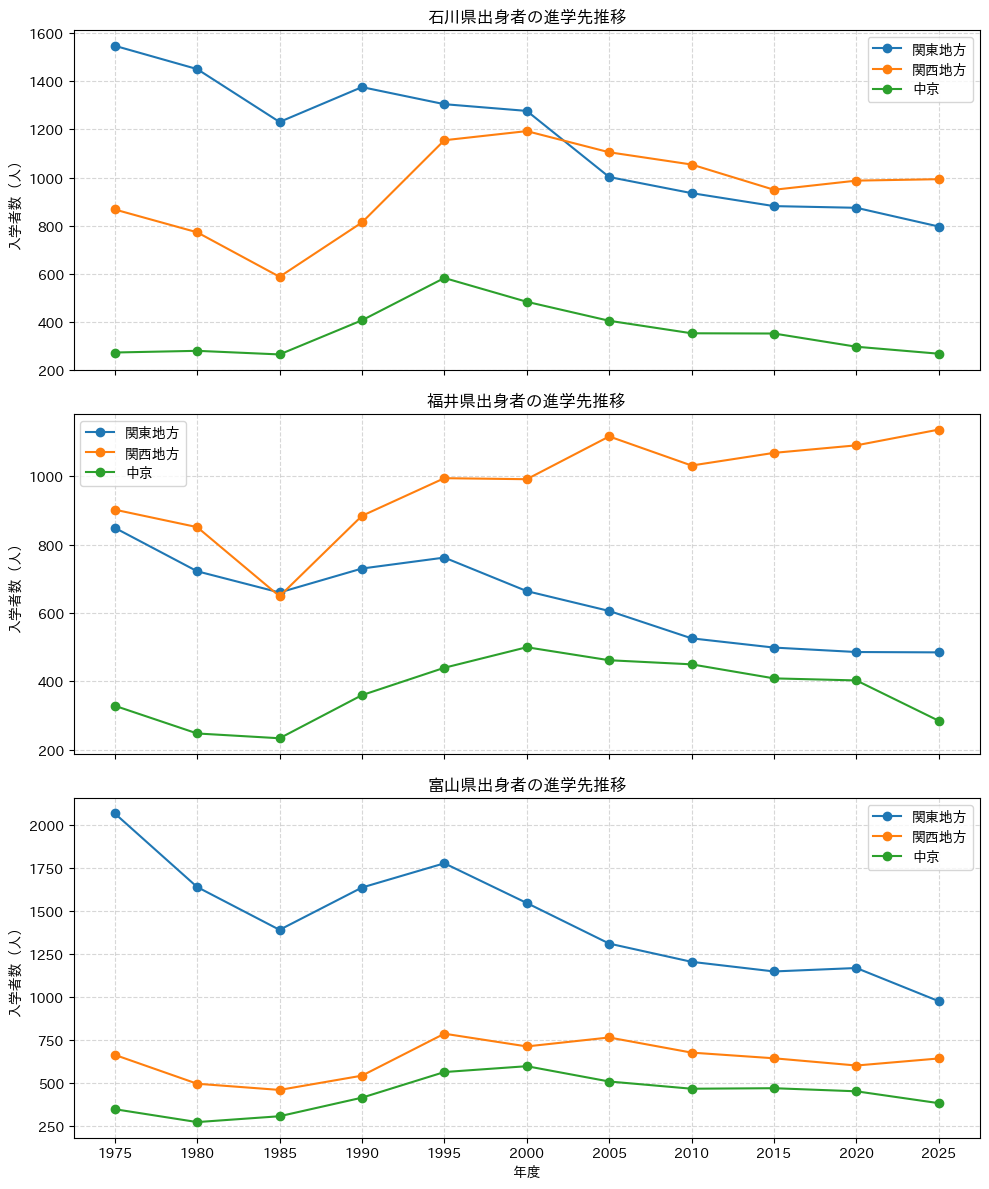

In [152]:
# 石川県・福井県・富山県を並べて比較する
origins = ['石川県', '福井県', '富山県']

# 3県について、対象年度・関東・関西・中京のデータを一括抽出して集計する
df_three_prefectures = (
    df_univ_migration[
        df_univ_migration['origin'].isin(origins)
        & df_univ_migration['year'].isin(target_years)
        & df_univ_migration['destination'].isin(region_map)
    ]
    # 進学先の都道府県名を関東地方・関西地方へ変換する
    .assign(destination=lambda df: df['destination'].map(region_map))
    .groupby(['year', 'origin', 'destination'], as_index=False)['students']
    .sum()
)

# 県ごとにグラフを分け、各グラフ内で関東・関西・中京を比較する
fig, axes = plt.subplots(len(origins), 1, figsize=(10, 12), sharex=True)
for ax, prefecture in zip(axes, origins):
    prefecture_data = df_three_prefectures[
        df_three_prefectures['origin'] == prefecture
    ]

    for region in ['関東地方', '関西地方', '中京']:
        region_data = prefecture_data[
            prefecture_data['destination'] == region
        ]
        ax.plot(
            region_data['year'],
            region_data['students'],
            marker='o',
            label=region,
        )

    ax.set_title(f'{prefecture}出身者の進学先推移')
    ax.set_ylabel('入学者数（人）')
    ax.set_xticks(list(target_years))
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

axes[-1].set_xlabel('年度')
plt.tight_layout()
plt.show()


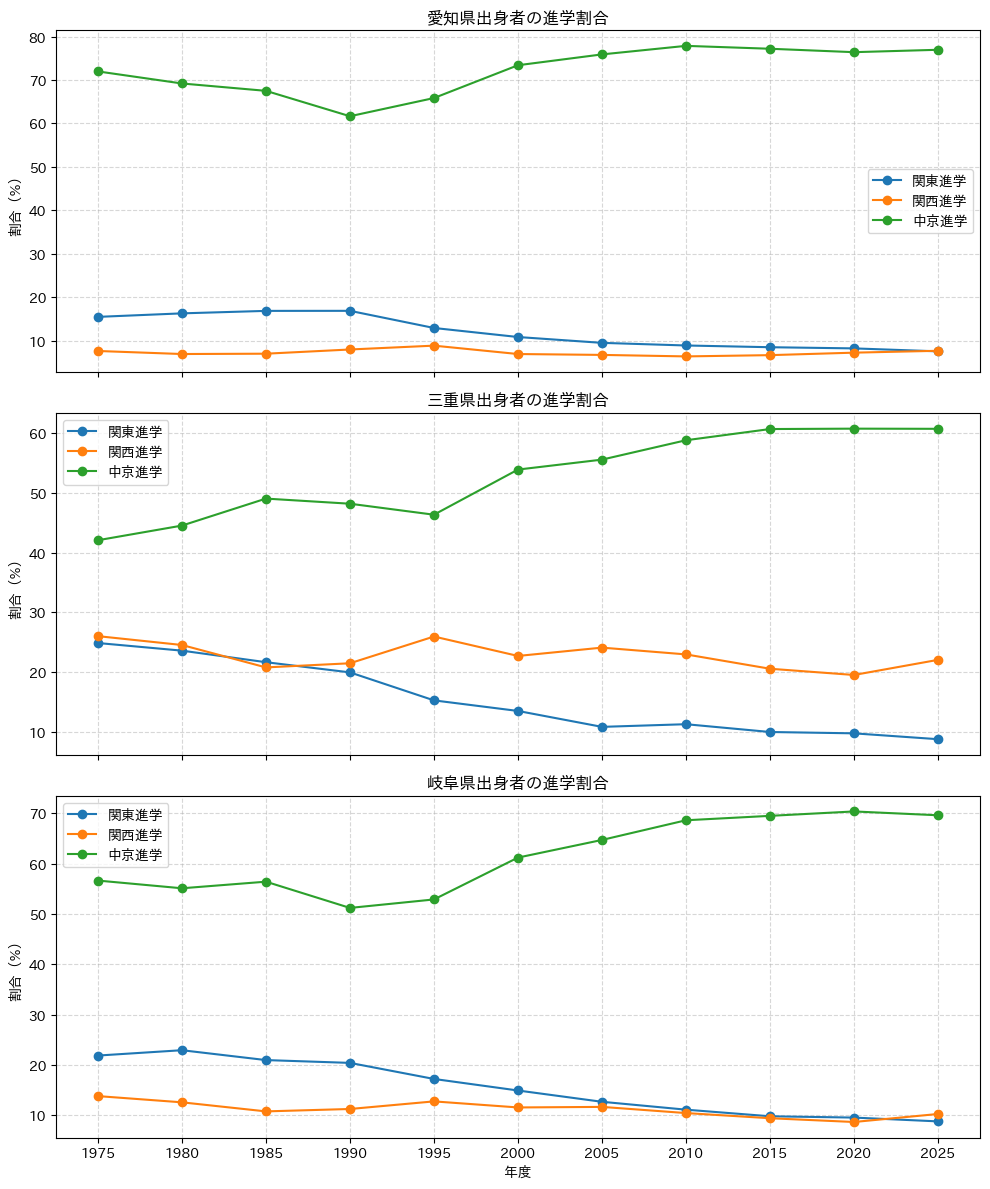

In [153]:
# 中京圏3県出身者の関東・関西・中京への進学割合を比較する
chukyo_prefectures = ['愛知県', '三重県', '岐阜県']

fig, axes = plt.subplots(
    len(chukyo_prefectures), 1, figsize=(10, 12), sharex=True
)

for ax, prefecture in zip(axes, chukyo_prefectures):
    prefecture_data = df_region[
        df_region['origin'] == prefecture
    ].drop_duplicates('year')

    for column, label in [
        ('関東進学割合', '関東進学'),
        ('関西進学割合', '関西進学'),
        ('中京進学割合', '中京進学'),
    ]:
        ax.plot(
            prefecture_data['year'],
            prefecture_data[column] * 100,
            marker='o', label=label
        )

    ax.set_title(f'{prefecture}出身者の進学割合')
    ax.set_ylabel('割合（%）')
    ax.set_xticks(list(target_years))
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

axes[-1].set_xlabel('年度')
plt.tight_layout()
plt.show()


In [154]:
# 割合で見ないとフェアではない
df_population = pd.read_csv('../data/national_census/population_prefecture.csv', skiprows=14)
df_population.head()

,表章項目 コード,表章項目 補助コード,表章項目,地域_時系列 コード,地域_時系列 補助コード,地域_時系列,/男女_時系列,総数,男,女,...,女.17,総数.18,男.18,女.18,総数.19,男.19,女.19,総数.20,男.20,女.20
0,20,NaN,人口【人】,0,NaN,全国,NaN,"55,963,053","28,044,185","27,918,868",...,"65,419,017","128,057,352","62,327,737","65,729,615","127,094,745","61,841,738","65,253,007","126,146,099","61,349,581","64,796,518"
1,20,NaN,人口【人】,100,NaN,人口集中地区,NaN,-,-,-,...,"43,003,820","86,121,462","42,051,390","44,070,072","86,868,176","42,363,423","44,504,753","88,285,927","42,973,052","45,312,875"
2,20,NaN,人口【人】,200,NaN,人口集中地区以外の地区,NaN,-,-,-,...,"22,415,197","41,935,890","20,276,347","21,659,543","40,226,569","19,478,315","20,748,254","37,860,172","18,376,529","19,483,643"
3,20,NaN,人口【人】,1000,NaN,北海道,NaN,"2,359,183","1,244,322","1,114,861",...,"2,952,704","5,506,419","2,603,345","2,903,074","5,381,733","2,537,089","2,844,644","5,224,614","2,465,088","2,759,526"
4,20,NaN,人口【人】,2000,NaN,青森県,NaN,"756,454","381,293","375,161",...,"757,580","1,373,339","646,141","727,198","1,308,265","614,694","693,571","1,237,984","583,402","654,582"


In [155]:
df_region

,year,origin,destination,students,全大学進学者数,関東進学割合,関西進学割合,中京進学割合
0,1975,三重県,中京,2447,5817,0.248410,0.259928,0.420664
1,1975,三重県,関東地方,1445,5817,0.248410,0.259928,0.420664
2,1975,三重県,関西地方,1512,5817,0.248410,0.259928,0.420664
3,1975,京都府,中京,306,9643,0.085865,0.824847,0.031733
4,1975,京都府,関東地方,828,9643,0.085865,0.824847,0.031733
...,...,...,...,...,...,...,...,...
1579,2025,鳥取県,関東地方,244,2348,0.103918,0.364991,0.015758
1580,2025,鳥取県,関西地方,857,2348,0.103918,0.364991,0.015758
1581,2025,鹿児島県,中京,149,6825,0.179194,0.106520,0.021832
1582,2025,鹿児島県,関東地方,1223,6825,0.179194,0.106520,0.021832


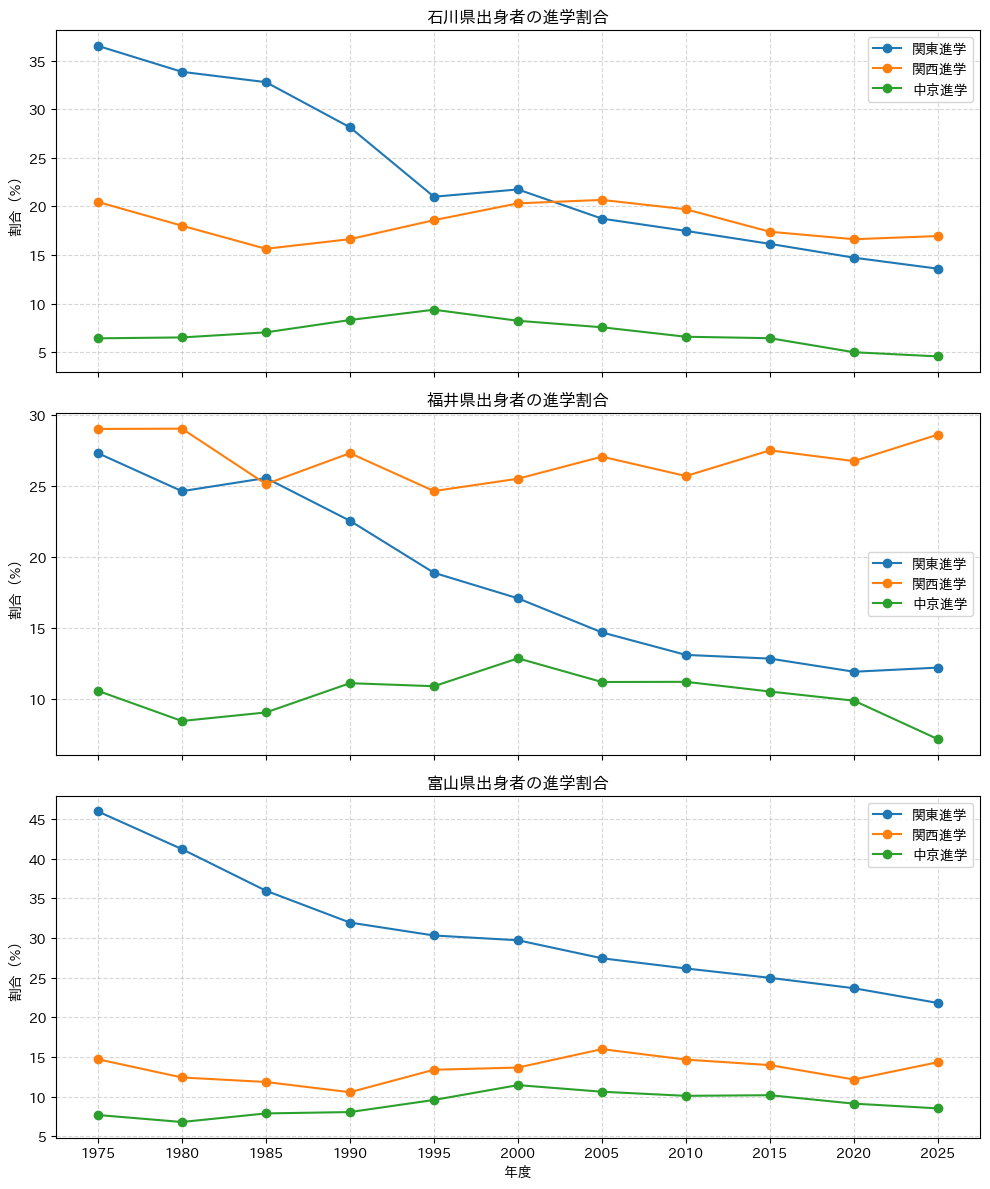

In [156]:
# 北陸3県の関東進学割合・関西進学割合・中京進学割合を比較する
hokuriku_prefectures = ['石川県', '福井県', '富山県']

fig, axes = plt.subplots(
    len(hokuriku_prefectures),
    1,
    figsize=(10, 12),
    sharex=True,
)

for ax, prefecture in zip(axes, hokuriku_prefectures):
    prefecture_data = df_region[
        df_region['origin'] == prefecture
    ].drop_duplicates('year')

    ax.plot(
        prefecture_data['year'],
        prefecture_data['関東進学割合'] * 100,
        marker='o',
        label='関東進学',
    )

    ax.plot(
        prefecture_data['year'],
        prefecture_data['関西進学割合'] * 100,
        marker='o',
        label='関西進学',
    )

    ax.plot(
        prefecture_data['year'],
        prefecture_data['中京進学割合'] * 100,
        marker='o',
        label='中京進学',
    )

    ax.set_title(f'{prefecture}出身者の進学割合')
    ax.set_ylabel('割合（%）')
    ax.set_xticks(list(target_years))
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

axes[-1].set_xlabel('年度')
plt.tight_layout()
plt.show()

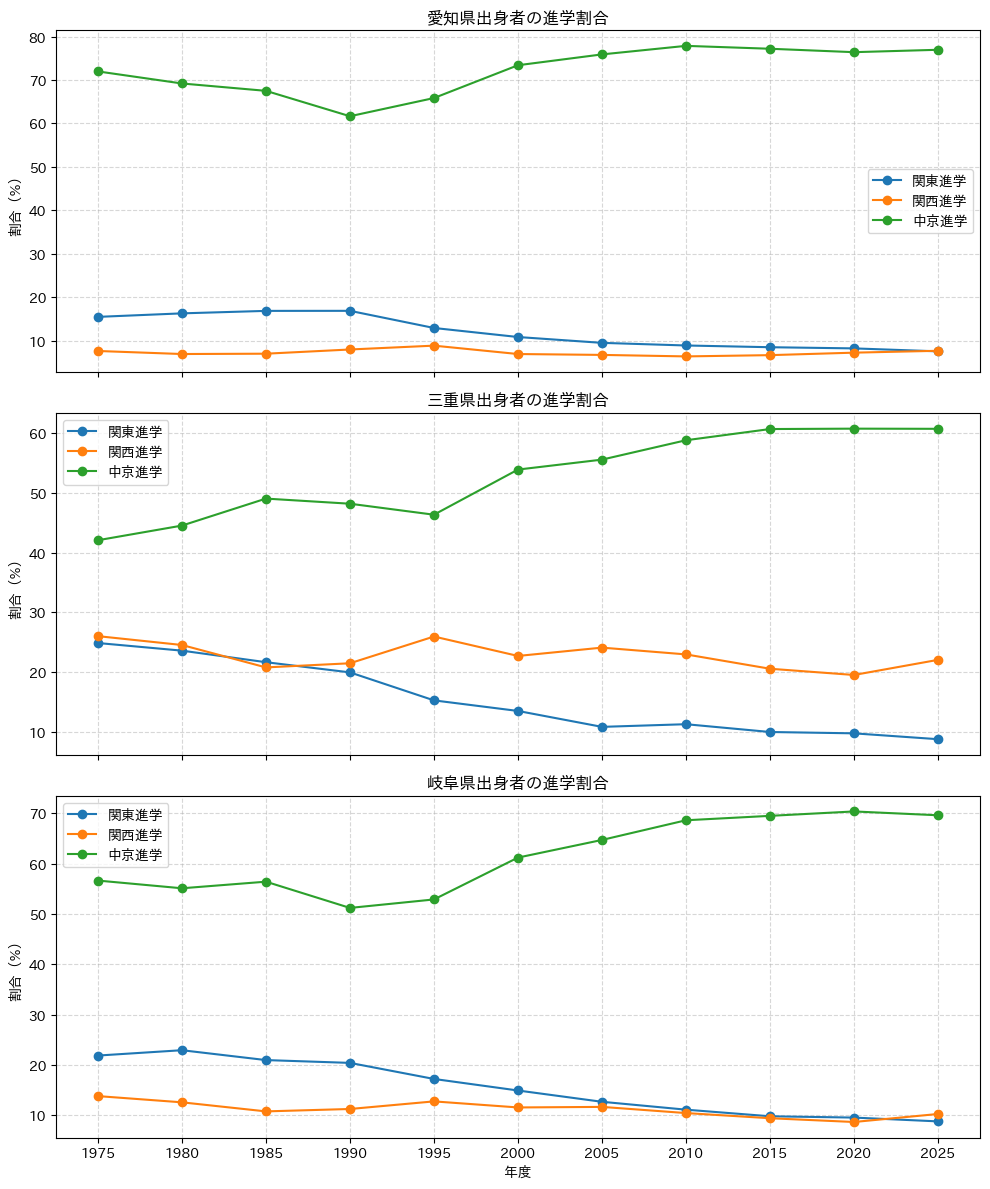

In [157]:
# 中京圏3県出身者の進学割合（ノートブック末尾のグラフ）
chukyo_prefectures = ['愛知県', '三重県', '岐阜県']
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

for ax, prefecture in zip(axes, chukyo_prefectures):
    prefecture_data = df_region[
        df_region['origin'] == prefecture
    ].drop_duplicates('year')
    for column, label in [
        ('関東進学割合', '関東進学'),
        ('関西進学割合', '関西進学'),
        ('中京進学割合', '中京進学'),
    ]:
        ax.plot(
            prefecture_data['year'],
            prefecture_data[column] * 100,
            marker='o',
            label=label,
        )
    ax.set_title(f'{prefecture}出身者の進学割合')
    ax.set_ylabel('割合（%）')
    ax.set_xticks(list(target_years))
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

axes[-1].set_xlabel('年度')
plt.tight_layout()
plt.show()


In [158]:
df_region.head()

,year,origin,destination,students,全大学進学者数,関東進学割合,関西進学割合,中京進学割合
0,1975,三重県,中京,2447,5817,0.248410,0.259928,0.420664
1,1975,三重県,関東地方,1445,5817,0.248410,0.259928,0.420664
2,1975,三重県,関西地方,1512,5817,0.248410,0.259928,0.420664
3,1975,京都府,中京,306,9643,0.085865,0.824847,0.031733
4,1975,京都府,関東地方,828,9643,0.085865,0.824847,0.031733


In [159]:
df_region = df_region.rename(columns={'全大学進学者数':'univ_enrollment', '関東進学割合':'kanto_enrollment_ratio', '関西進学割合': 'kansai_enrollment_ratio', '中京進学割合':'cyukyo_enrollment_ratio'})
df_region.head()

,year,origin,destination,students,univ_enrollment,kanto_enrollment_ratio,kansai_enrollment_ratio,cyukyo_enrollment_ratio
0,1975,三重県,中京,2447,5817,0.248410,0.259928,0.420664
1,1975,三重県,関東地方,1445,5817,0.248410,0.259928,0.420664
2,1975,三重県,関西地方,1512,5817,0.248410,0.259928,0.420664
3,1975,京都府,中京,306,9643,0.085865,0.824847,0.031733
4,1975,京都府,関東地方,828,9643,0.085865,0.824847,0.031733


In [160]:
# 関西より関東圏への進学が多いところ
df_region[(df_region['kanto_enrollment_ratio'] > df_region['kansai_enrollment_ratio']) & (df_region['destination'] == '関東地方') & (df_region['year'] == 2025)]

,year,origin,destination,students,univ_enrollment,kanto_enrollment_ratio,kansai_enrollment_ratio,cyukyo_enrollment_ratio
1447,2025,佐賀県,関東地方,523,3606,0.145036,0.079035,0.008874
1450,2025,全国平均,関東地方,270764,623307,0.434399,0.210845,0.081563
1456,2025,北海道,関東地方,3863,21727,0.177797,0.061122,0.015281
1459,2025,千葉県,関東地方,29823,31355,0.951140,0.011194,0.005422
1465,2025,埼玉県,関東地方,34257,35900,0.954234,0.008719,0.002228
1468,2025,大分県,関東地方,422,4383,0.096281,0.089208,0.011636
1477,2025,宮城県,関東地方,2467,10343,0.238519,0.024268,0.007735
1480,2025,宮崎県,関東地方,606,4199,0.144320,0.086687,0.018338
1483,2025,富山県,関東地方,974,4467,0.218043,0.143497,0.085292
1489,2025,山形県,関東地方,1415,4092,0.345797,0.018817,0.006354


In [161]:
# 全国平均を計算
df_all_country = df_region[df_region['origin'] == '全国平均']
df_all_country

,year,origin,destination,students,univ_enrollment,kanto_enrollment_ratio,kansai_enrollment_ratio,cyukyo_enrollment_ratio
9,1975,全国平均,中京,31620,423207,0.479586,0.205937,0.074715
10,1975,全国平均,関東地方,202964,423207,0.479586,0.205937,0.074715
11,1975,全国平均,関西地方,87154,423207,0.479586,0.205937,0.074715
153,1980,全国平均,中京,29281,411280,0.467492,0.203686,0.071195
154,1980,全国平均,関東地方,192270,411280,0.467492,0.203686,0.071195
155,1980,全国平均,関西地方,83772,411280,0.467492,0.203686,0.071195
297,1985,全国平均,中京,29785,409515,0.464769,0.197158,0.072732
298,1985,全国平均,関東地方,190330,409515,0.464769,0.197158,0.072732
299,1985,全国平均,関西地方,80739,409515,0.464769,0.197158,0.072732
441,1990,全国平均,中京,35284,486946,0.451715,0.198398,0.072460


In [163]:
non_kanto = df_univ_migration[
    df_univ_migration['year'].isin(target_years)
    & ~df_univ_migration['origin'].isin(kanto_region)
]

non_kanto_region = (
    non_kanto[non_kanto['destination'].isin(region_map)]
    .assign(destination=lambda df: df['destination'].map(region_map))
    .groupby(['year', 'destination'], as_index=False)['students']
    .sum()
)

non_kanto_total = (
    non_kanto
    .groupby('year', as_index=False)['students']
    .sum()
    .rename(columns={'students': 'univ_enrollment'})
)

non_kanto_shares = (
    non_kanto_region
    .pivot(index='year', columns='destination', values='students')
    .fillna(0)
    .reset_index()
    .rename(columns={
        '関東地方': '関東進学者数',
        '関西地方': '関西進学者数',
        '中京': '中京進学者数',
    })
    .merge(non_kanto_total, on='year', validate='one_to_one')
)

for region, students_column, ratio_column in [
    ('関東地方', '関東進学者数', 'kanto_enrollment_ratio'),
    ('関西地方', '関西進学者数', 'kansai_enrollment_ratio'),
    ('中京', '中京進学者数', 'cyukyo_enrollment_ratio'),
]:
    non_kanto_shares[ratio_column] = (
        non_kanto_shares[students_column]
        / non_kanto_shares['univ_enrollment']
    )

non_kanto_region = non_kanto_region.merge(
    non_kanto_shares[
        [
            'year',
            'univ_enrollment',
            'kanto_enrollment_ratio',
            'kansai_enrollment_ratio',
            'cyukyo_enrollment_ratio',
        ]
    ],
    on='year',
    validate='many_to_one',
)

non_kanto_region['origin'] = '関東除く全国平均'

df_region = pd.concat(
    [df_region, non_kanto_region],
    ignore_index=True,
)

In [164]:
df_region[df_region['origin'] == '関東除く全国平均']

,year,origin,destination,students,univ_enrollment,kanto_enrollment_ratio,kansai_enrollment_ratio,cyukyo_enrollment_ratio
1584,1975,関東除く全国平均,中京,31170,303626,0.293417,0.283447,0.102659
1585,1975,関東除く全国平均,関東地方,89089,303626,0.293417,0.283447,0.102659
1586,1975,関東除く全国平均,関西地方,86062,303626,0.293417,0.283447,0.102659
1587,1980,関東除く全国平均,中京,28829,285361,0.258795,0.289325,0.101026
1588,1980,関東除く全国平均,関東地方,73850,285361,0.258795,0.289325,0.101026
1589,1980,関東除く全国平均,関西地方,82562,285361,0.258795,0.289325,0.101026
1590,1985,関東除く全国平均,中京,29262,272909,0.230630,0.290676,0.107223
1591,1985,関東除く全国平均,関東地方,62941,272909,0.230630,0.290676,0.107223
1592,1985,関東除く全国平均,関西地方,79328,272909,0.230630,0.290676,0.107223
1593,1990,関東除く全国平均,中京,34664,324623,0.214920,0.291892,0.106782


In [169]:
national = (
    df_region[df_region['origin'] == '全国平均']
    .drop_duplicates('year')
    .sort_values('year')
)

non_kanto_national = (
    df_region[df_region['origin'] == '関東除く全国平均']
    .drop_duplicates('year')
    .sort_values('year')
)

print(national[['year', 'origin', 'kanto_enrollment_ratio']])
print(non_kanto_national[['year', 'origin', 'kanto_enrollment_ratio']])

      year origin  kanto_enrollment_ratio
9     1975   全国平均                0.479586
153   1980   全国平均                0.467492
297   1985   全国平均                0.464769
441   1990   全国平均                0.451715
585   1995   全国平均                0.430496
729   2000   全国平均                0.434179
873   2005   全国平均                0.430192
1017  2010   全国平均                0.442575
1161  2015   全国平均                0.440336
1305  2020   全国平均                0.431445
1449  2025   全国平均                0.434399
      year    origin  kanto_enrollment_ratio
1584  1975  関東除く全国平均                0.293417
1587  1980  関東除く全国平均                0.258795
1590  1985  関東除く全国平均                0.230630
1593  1990  関東除く全国平均                0.214920
1596  1995  関東除く全国平均                0.189494
1599  2000  関東除く全国平均                0.185116
1602  2005  関東除く全国平均                0.172010
1605  2010  関東除く全国平均                0.169382
1608  2015  関東除く全国平均                0.159462
1611  2020  関東除く全国平均                0.150826
1

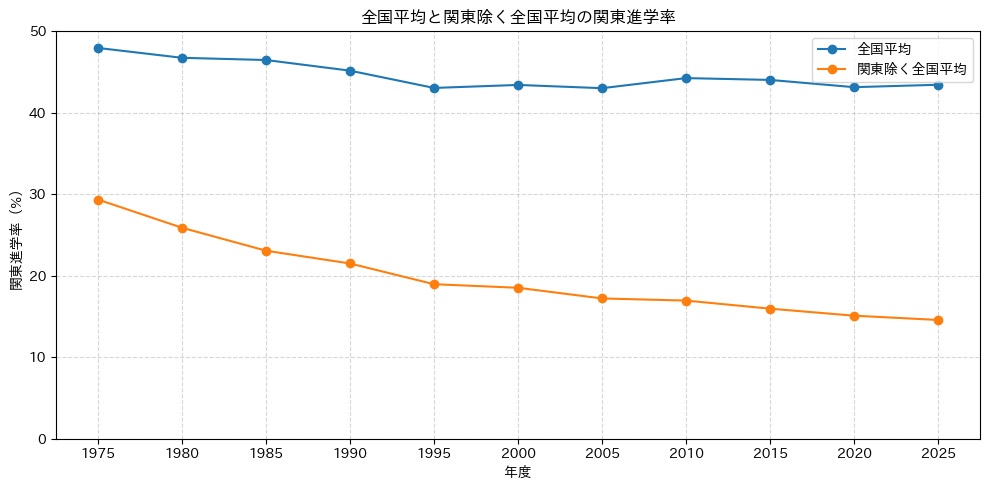

In [172]:
plt.figure(figsize=(10, 5))

plt.plot(
    national['year'],
    national['kanto_enrollment_ratio'] * 100,
    marker='o',
    label='全国平均',
    zorder=2,
)

plt.plot(
    non_kanto_national['year'],
    non_kanto_national['kanto_enrollment_ratio'] * 100,
    marker='o',
    label='関東除く全国平均',
    zorder=3,
)

plt.title('全国平均と関東除く全国平均の関東進学率')
plt.xlabel('年度')
plt.ylabel('関東進学率（%）')
plt.ylim(0, 50)
plt.xticks(sorted(national['year']))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()